# 05 · Trap 3: a segment where the result reverses

An average treatment effect is a weighted average of segment effects. A positive average
can hide a segment that is genuinely harmed. The danger runs both ways, though:

* **Missing a real reversal** ships a change that hurts 45% of users.
* **Inventing one** by slicing the data 20 ways until something looks bad (or good) is
  p-hacking, and "ship to segment X only" decisions built on it fail to replicate.

The defence is the same as for peeking: **decide in advance** which segments matter and why.
We pre-registered platform (notebook 01) with a mechanism: the photo-heavy menu is heavier,
and our Android base skews toward lower-end devices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from pizza_ab.simulate import load_or_simulate
from pizza_ab.metrics import user_metrics, long_run_user
from pizza_ab.stats import mean_test, ratio_test, holm, interaction_z
from pizza_ab.config import PLATFORMS, REGIONS, PRIMARY_READ_DAY
from pizza_ab import plots

plots.set_style()
users, orders = load_or_simulate("experiment")
m = user_metrics(users, orders[orders["day"] < PRIMARY_READ_DAY])   # primary, as read on day 21
lr = long_run_user(users, orders)                                    # days 7+ since exposure, through day 27

def primary(df):
    return mean_test(df.loc[df.variant == "control", "converted"], df.loc[df.variant == "treatment", "converted"])

def long_run(df):
    c, t = df[df.variant == "control"], df[df.variant == "treatment"]
    return ratio_test(c["lr_orders"], c["lr_days"], t["lr_orders"], t["lr_days"])

## 1. The pre-registered segment: platform

In [2]:
rows = []
for seg in ["All"] + PLATFORMS:
    mm = m if seg == "All" else m[m.platform == seg]
    ll = lr if seg == "All" else lr[lr.platform == seg]
    for name, r in [("7-day conversion (primary)", primary(mm)), ("orders/user-day, weeks 2–4", long_run(ll))]:
        rows.append({"segment": seg, "metric": name, "share of users": len(mm) / len(m),
                     "lift": r.rel_lift, "ci_low": r.rel_ci[0], "ci_high": r.rel_ci[1], "p": r.p_value})
seg_tbl = pd.DataFrame(rows).set_index(["metric", "segment"]).sort_index(level=0, sort_remaining=False)
fmt = {"share of users": "{:.0%}", "lift": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}", "p": "{:.1e}"}
seg_tbl.style.format(fmt)

Is the iOS–Android difference itself significant? Comparing "iOS significant, Android not"
is **not** a test of a difference — you must test the interaction directly.

In [3]:
for metric in seg_tbl.index.levels[0]:
    a, b = seg_tbl.loc[(metric, "iOS")], seg_tbl.loc[(metric, "Android")]
    p = interaction_z(a.lift, (a.ci_low, a.ci_high), b.lift, (b.ci_low, b.ci_high))
    print(f"{metric:40s} iOS {a.lift:+.1%} vs Android {b.lift:+.1%}  → interaction p = {p:.1e}")

7-day conversion (primary)               iOS +13.6% vs Android -1.2%  → interaction p = 8.0e-06
orders/user-day, weeks 2–4               iOS +8.3% vs Android -7.0%  → interaction p = 1.6e-10


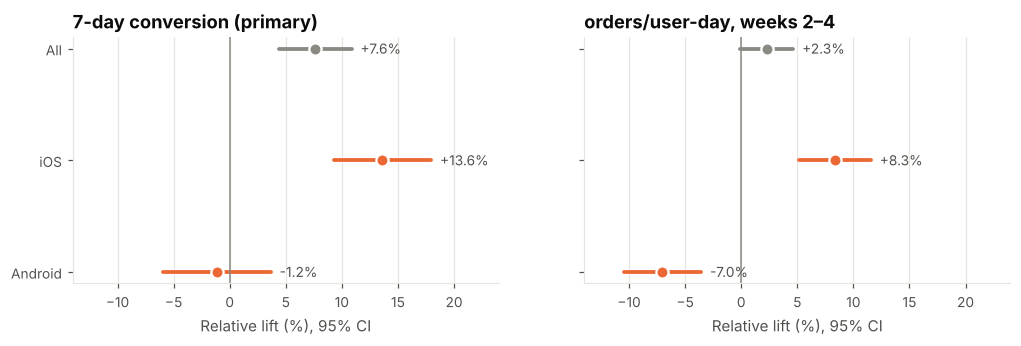

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
for ax, metric in zip(axes, ["7-day conversion (primary)", "orders/user-day, weeks 2–4"]):
    sub = seg_tbl.loc[metric].loc[["All"] + PLATFORMS]
    y = np.arange(len(sub))[::-1]
    for yi, (seg, r) in zip(y, sub.iterrows()):
        color = plots.MUTED if seg == "All" else plots.TREATMENT
        ax.plot([r.ci_low * 100, r.ci_high * 100], [yi, yi], color=color, lw=2.5, solid_capstyle="round")
        ax.plot(r.lift * 100, yi, "o", color=color, ms=8, mec="white", mew=1.5)
        ax.text(r.ci_high * 100 + 0.8, yi, f"{r.lift:+.1%}", va="center", fontsize=9, color=plots.TEXT_2)
    ax.axvline(0, color=plots.MUTED, lw=1)
    ax.set_yticks(y, sub.index)
    ax.set_xlim(-14, 24)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_title(metric)
    ax.set_xlabel("Relative lift (%), 95% CI")
plots.save(fig, "05_platform_forest");

**The reversal.** In weeks 2–4 iOS gains ~8% and Android *loses* ~7%. In week 1 the
novelty boost lifts Android to roughly zero, which is why the primary metric shows Android as
"flat" rather than harmed: novelty and segment heterogeneity were hiding each other.

## 2. Mechanism: does load time explain it?

A segment result we can explain is far more credible than one we can't. The guardrail
that failed overall in notebook 02 is the obvious candidate.

In [5]:
g = users.groupby(["platform", "variant"])["menu_load_s"]
lt = pd.DataFrame({
    "mean, control (s)": g.mean().xs("control", level="variant"),
    "mean, treatment (s)": g.mean().xs("treatment", level="variant"),
    "p75, control (s)": g.quantile(0.75).xs("control", level="variant"),
    "p75, treatment (s)": g.quantile(0.75).xs("treatment", level="variant"),
})
lt["mean change"] = lt["mean, treatment (s)"] / lt["mean, control (s)"] - 1
lt["p75 change"] = lt["p75, treatment (s)"] / lt["p75, control (s)"] - 1
lt["guardrail (≤ +10%)"] = np.where(lt["p75 change"] <= 0.10, "PASS", "FAIL")
lt.style.format({c: "{:.2f}" for c in lt.columns[:4]} | {"mean change": "{:+.0%}", "p75 change": "{:+.0%}"})

,"mean, control (s)","mean, treatment (s)","p75, control (s)","p75, treatment (s)",mean change,p75 change,guardrail (≤ +10%)
platform,,,,,,,
Android,1.67,2.58,1.96,2.86,+54%,+46%,FAIL
iOS,1.15,1.23,1.35,1.43,+7%,+6%,PASS


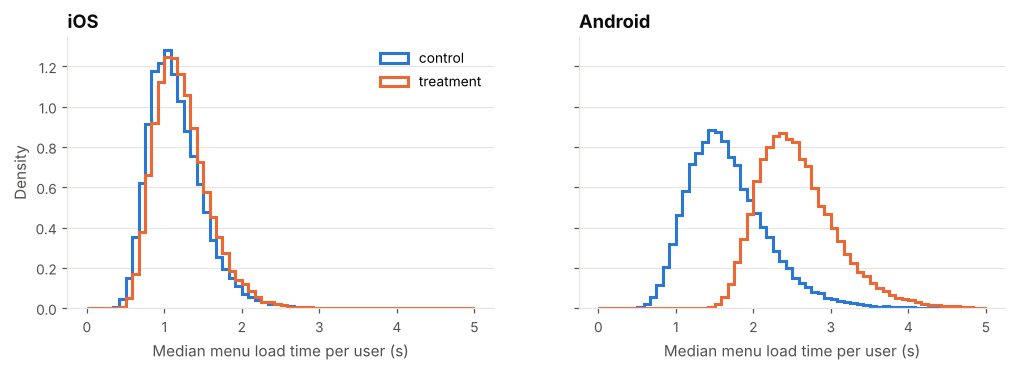

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
bins = np.linspace(0, 5, 61)
for ax, plat in zip(axes, PLATFORMS):
    for v in ["control", "treatment"]:
        x = users.loc[(users.platform == plat) & (users.variant == v), "menu_load_s"]
        ax.hist(x, bins=bins, histtype="step", lw=2, color=plots.ARM_COLORS[v], density=True, label=v)
    ax.set_title(plat)
    ax.set_xlabel("Median menu load time per user (s)")
axes[0].set_ylabel("Density")
axes[0].legend()
plots.save(fig, "05_load_time");

On iOS the new page is ~0.1 s slower (+7%, inside the guardrail). On Android it is ~0.9 s
slower (+54% on average, +46% at p75). Latency costing conversions is one of the best-documented effects in
e-commerce, so the mechanism is plausible.

Be honest about what this shows: load time was *changed by the treatment*, so we cannot
randomize it here, and "Android users with slower phones convert less" would be
correlational. The causal test is the follow-up: fix Android image loading and re-test.

## 3. Is this Simpson's paradox?

**No** — and interviewers check whether you know the difference.

* What we have is **effect heterogeneity**: the overall weeks 2–4 effect (+2%) is the
  weighted average of +8% and −7%. Nothing paradoxical; the average is between its parts.
* **Simpson's paradox** is when *every* segment moves one way and the pooled result moves the
  other. If the allocation ratio is the same in every stratum (as in a randomized test with a fixed
  split), it can't happen, because the segment mix is then the same in both arms. It appears when allocation is *unequal across strata* — the classic case
  is pooling data across a ramp-up where the treatment share changed over time:

In [7]:
ramp = pd.DataFrame({
    "week": ["week 1 (promo week, ramp at 10%)"] * 2 + ["week 2 (normal, 50/50)"] * 2,
    "variant": ["control", "treatment"] * 2,
    "users": [90_000, 10_000, 50_000, 50_000],
    "conversion": [0.150, 0.1575, 0.100, 0.105],     # treatment is +5% in BOTH weeks
})
ramp["orders"] = ramp["users"] * ramp["conversion"]
pooled = ramp.groupby("variant")[["orders", "users"]].sum()
pooled["conversion"] = pooled["orders"] / pooled["users"]
display(ramp.pivot(index="week", columns="variant", values="conversion").assign(
    lift=lambda d: d.treatment / d.control - 1).style.format("{:.2%}"))
print(f"Pooled: control {pooled.loc['control','conversion']:.2%}, treatment {pooled.loc['treatment','conversion']:.2%} "
      f"→ pooled lift {pooled.loc['treatment','conversion']/pooled.loc['control','conversion']-1:+.1%}")

variant,control,treatment,lift
week,,,
"week 1 (promo week, ramp at 10%)",15.00%,15.75%,5.00%
"week 2 (normal, 50/50)",10.00%,10.50%,5.00%


Pooled: control 13.21%, treatment 11.38% → pooled lift -13.9%


+5% in each week, −14% pooled, because most treatment users arrived in the low-conversion
week. Fix: analyse only the period with a stable split, or stratify by period.

## 4. Exploratory segments: how *not* to find a reversal

Now the forking-paths danger. Region was **not** pre-registered and there is no mechanism
for it. Slice the weeks 2–4 metric by six regions:

In [8]:
reg_rows = []
for reg in REGIONS:
    r = long_run(lr[lr.region == reg])
    reg_rows.append({"region": reg, "lift": r.rel_lift, "ci_low": r.rel_ci[0], "ci_high": r.rel_ci[1], "p": r.p_value})
reg = pd.DataFrame(reg_rows).set_index("region")
reg["p (Holm-adjusted)"] = holm(reg["p"])

def cochran_q(tbl):
    """Heterogeneity test: do the segment lifts differ more than sampling noise allows?"""
    se = (tbl["ci_high"] - tbl["ci_low"]) / (2 * 1.96)
    w = 1 / se**2
    pooled = (w * tbl["lift"]).sum() / w.sum()
    q = (w * (tbl["lift"] - pooled) ** 2).sum()
    return q, stats.chi2.sf(q, len(tbl) - 1)

q_reg, p_reg = cochran_q(reg)
q_plat, p_plat = cochran_q(seg_tbl.loc["orders/user-day, weeks 2–4"].loc[PLATFORMS])
print(f"Heterogeneity across regions:   Q = {q_reg:.1f} on {len(reg)-1} df, p = {p_reg:.2f}")
print(f"Heterogeneity across platforms: Q = {q_plat:.1f} on 1 df, p = {p_plat:.1e}")
reg.style.format({"lift": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}", "p": "{:.3f}", "p (Holm-adjusted)": "{:.3f}"})

Heterogeneity across regions:   Q = 7.9 on 5 df, p = 0.16
Heterogeneity across platforms: Q = 40.9 on 1 df, p = 1.6e-10


,lift,ci_low,ci_high,p,p (Holm-adjusted)
region,,,,,
North,+6.0%,+0.8%,+11.1%,0.020,0.122
South,-0.8%,-5.9%,+4.4%,0.773,1.000
East,+6.4%,+0.5%,+12.3%,0.028,0.138
West,-2.2%,-7.8%,+3.5%,0.453,1.000
Central,+2.5%,-3.9%,+8.9%,0.444,1.000
Coast,+0.0%,-7.4%,+7.5%,0.994,1.000


Two regions, North and East, come out "significant" at p < 0.05 with lifts around +6%. A
hurried analyst could write "ship to North and East". But slicing six ways gives six chances for
one region to look special by luck (with six independent tests at α = 0.05, the chance of
at least one false positive is 1 − 0.95⁶ ≈ 26%). The
heterogeneity test says the spread is what noise alone produces, and after a Holm
correction for testing six regions nothing stands out. Platform, by contrast, is strongly
heterogeneous, pre-registered, and has a mechanism.

## 5. Takeaways

* **The reversal is real**: in weeks 2–4 Android loses ≈ 7% of orders and iOS gains ≈ 8%.
  Interaction p ≈ 2·10⁻¹⁰, pre-registered, with a plausible mechanism in the failed guardrail.
* The two traps compounded: novelty made Android look flat in week 1, and the iOS gain made
  the blended average look positive. Either trap alone would have hidden the harm.
* Credibility checklist for a segment finding: **pre-registered? mechanism? interaction test
  (not "significant here, not there")? survives multiple-testing correction?** Platform passes
  all four; region passes none.